# 1. ACC and nRMSE of SamudrACE and E3SM hindcasts (ESP-Lab metrics)

Gridded and Niño 3.4 skill for the merged hindcasts (`VAR(start_date, [ensemble], lead, lat, lon)` on the SamudrACE 1° grid), computed with ESP-Lab's skill functions:

- `esp_lab.stats.remove_drift`: removes the lead-dependent model climatology (drift) over `CLIM_YEARS`, separately for each initialization month.
- `esp_lab.stats.compute_skill_seasonal(..., monthly=True, detrend=True)`: ensemble-mean anomaly correlation (`corr`, ACC), an effective-sample-size p-value (`pval`), and normalized RMSE (`rmse` = RMSE / σ_ref), all after linear detrending of both forecast and reference over the start years. nRMSE < 1 beats a climatological (zero-anomaly) forecast.

Every variable is scored with the same three comparisons:

1. **E3SM vs obs**
2. **SamudrACE vs obs**
3. **SamudrACE vs E3SM**, with the E3SM ensemble mean treated as truth

The reference series for each lead is built from the reference's own fields at that lead's verification months. Its climatology is removed by `compute_skill_seasonal`, which is equivalent to removing the reference's drift. All three comparisons use the same start dates (the intersection of the three files) and the same surface mask.

**Conventions:** this notebook reports leads like `acc_analysis.ipynb`, as months with lead 0 = initialization month. Internally ESP-Lab uses `L = lead + 1`. May and November starts are scored separately, because ESP-Lab skill is computed per initialization month.

**Optional coarsening:** `COARSEN_TO = 5.0` applies ESP-Lab's conservative regridder (the 5°×5° grid of the 1a/1b notebooks) to every field before scoring. Use it to compare with those figures or to reduce gridpoint noise, especially for precipitation.

## Observational references

Regridded to the SamudrACE grid by `0-regrid-obs.ipynb` (ESP-Lab conservative regridding) and stored in `merged/<tag>_<VAR>_samudrace.nc`. Sources are under `/global/cfs/cdirs/e3sm/e3sm_diags/obs_for_e3sm_diags/time-series` (`esp_lab.env_paths.obs_root()`).

| Variable | Product | File | Notes |
|---|---|---|---|
| PRECT | GPCP v2.3 | `GPCP_v2.3/PRECT_197901_201712.nc` | 2.5°, mm/d; ends 2017-12, so starts after 2015 are dropped |
| TS | ERA5 | `ERA5/ts_197901_201912.nc` | land + ocean, no mask needed; ESP-Lab's TS reference; ends 2019-12 |
| TREFHT | ERA5 | `ERA5/tas_197901_201912.nc` | |
| PSL | ERA5 | `ERA5/psl_197901_201912.nc` | for Niño 3.4 teleconnections |
| LHFLX | ERA5 | `ERA5/hfls_197901_201912.nc` | land + ocean, positive upward like E3SM |
| LHFLX | OAFlux | `OAFlux/LHFLX_197901_201312.nc` | ocean only; ends 2013 |
| TS / SST | HadISST2 | `HadISST2/ts_186901_202212.nc`, `HadISST2/tos_186901_202212.nc` (`sst`) | land values are filler, so the ocean mask is applied automatically |
| Niño 3.4 index | NOAA PSL (HadISST) | `ESP-Lab/external/nino34.HadISST.PSL.csv` | monthly anomaly index via `index_reference_skill.load_psl_index("Nino3.4")`; no regridding |

Note: all SamudrACE members for a start date share the EN00 initial condition, whereas E3SM members EN00–EN09 have distinct initial conditions.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from calendar import month_abbr
from pathlib import Path
import warnings

ESP_LAB_ROOT = Path("/pscratch/sd/e/edejong/ESP-Lab")
if str(ESP_LAB_ROOT) not in sys.path:
    sys.path.insert(0, str(ESP_LAB_ROOT))

import cftime
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from esp_lab import stats as esp_stats
from esp_lab import index_reference_skill
from esp_lab.utils import regrid_utils as regrid
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf
from esp_lab.utils.unit_conversion import (
    convert_kelvin_to_celsius, convert_pa_to_hpa, convert_precip_mps_to_mmday, no_unit_conversion,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=SyntaxWarning)
warnings.filterwarnings("ignore", category=FutureWarning, message=r"Deleting a single level of a MultiIndex is deprecated.*")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

/global/common/software/e3sm/anaconda_envs/e3smu_1_13_0/pm-cpu/pixi_login/.pixi/envs/default/lib/python3.13/site-packages/properscoring/_crps.py:257: SyntaxWarning: invalid escape sequence '\i'
  CRPS(F, x) = \int_z (F(z) - H(z - x))^2 dz
/global/common/software/e3sm/anaconda_envs/e3smu_1_13_0/pm-cpu/pixi_login/.pixi/envs/default/lib/python3.13/site-packages/properscoring/_brier.py:10: SyntaxWarning: invalid escape sequence '\i'
  The Brier score (BS) scores binary forecasts $k \in \{0, 1\}$,
/global/common/software/e3sm/anaconda_envs/e3smu_1_13_0/pm-cpu/pixi_login/.pixi/envs/default/lib/python3.13/site-packages/properscoring/_brier.py:102: SyntaxWarning: invalid escape sequence '\i'
  CRPS(F, x) = \int_z BS(F(z), H(z - x)) dz


## Configuration

In [2]:
SAM_DIR = Path("/pscratch/sd/e/edejong/samudrace/hist-2y_runs_v0/analysis")
ANALYSIS_DIR = Path.cwd()
DATA_DIR = SAM_DIR / "merged"
CACHE_DIR = ANALYSIS_DIR / "skill_cache"
FIGURE_DIR = ANALYSIS_DIR / "skill_figures"
SAVE_FIGURES = True
TARGET_GRID = "samudrace"

VARIABLE = "TS"
SAMUDRACE_CASE = "C1A1-01mo-EN00"

# Observational reference per variable; file tags match 0-regrid-obs.ipynb outputs
OBS_BY_VARIABLE = {"TS": "ERA5", "TREFHT": "ERA5", "PSL": "ERA5", "LHFLX": "ERA5", "PRECT": "GPCP", "SST": "HadISST2"}
OBS_PRODUCT = OBS_BY_VARIABLE[VARIABLE]   # e.g. "HadISST2" for an SST-based TS reference
OCEAN_ONLY_OBS = {"HadISST2", "OAFlux"}
SURFACE_MASK = "ocean" if OBS_PRODUCT in OCEAN_ONLY_OBS else None   # or force "ocean" / "land" / None
LANDFRAC_FILE = Path("/pscratch/sd/e/edejong/samudrace/e3smv3-lr-hist-samudrace/forcing_data/atmosphere-forcing-1980.nc")
LANDFRAC_THRESHOLD = 0.5

UNIT_CONVERSIONS = {
    "TS": convert_kelvin_to_celsius,
    "TREFHT": convert_kelvin_to_celsius,
    "SST": convert_kelvin_to_celsius,
    "PRECT": convert_precip_mps_to_mmday,
    "PSL": convert_pa_to_hpa,
    "LHFLX": lambda da: no_unit_conversion(da, units="W m-2"),
}

COARSEN_TO = None          # None = native 1° grid; 5.0 = ESP-Lab 5°x5° conservative grid
INIT_MONTHS = [5, 11]
CLIM_YEARS = (1981, 2010)
DETREND = True
ALPHA = 0.05               # significance level for ACC hatching and markers
FORCE_RECOMPUTE = False

MAP_LEADS = [0, 3, 6, 12]  # lead months (0 = initialization month)
REGIONS = {
    "global": dict(lat=(-90, 90), lon=(0, 360)),
    "tropics": dict(lat=(-20, 20), lon=(0, 360)),
    "nino34": dict(lat=(-5, 5), lon=(190, 240)),
    "north_atlantic": dict(lat=(0, 60), lon=(280, 360)),
    "conus": dict(lat=(24, 50), lon=(235, 294))
}
SUMMARY_REGIONS = ["global", "tropics", "nino34", "north_atlantic", "conus"]

# Niño 3.4 is always computed from TS, independently of VARIABLE
NINO_REGION = REGIONS["nino34"]
NINO_OBS_PRODUCT = "HadISST2"
INCLUDE_PSL_INDEX = True

OBS_FILE_TAGS = {"ERA5": "era5", "GPCP": "gpcp", "HadISST2": "hadisst2", "OAFlux": "oaflux"}


def merged_paths(variable, obs_product):
    return {
        "E3SM": DATA_DIR / f"e3sm_{variable}_{TARGET_GRID}.nc",
        "SamudrACE": DATA_DIR / f"samudrace-{SAMUDRACE_CASE}_{variable}_{TARGET_GRID}.nc",
        obs_product: DATA_DIR / f"{OBS_FILE_TAGS[obs_product]}_{variable}_{TARGET_GRID}.nc",
    }


DATASETS = merged_paths(VARIABLE, OBS_PRODUCT)
COMPARISONS = [("E3SM", OBS_PRODUCT), ("SamudrACE", OBS_PRODUCT), ("SamudrACE", "E3SM")]
DISPLAY = {"E3SM": "E3SM", "SamudrACE": f"SamudrACE {SAMUDRACE_CASE}"}
FILE_TAGS = {"E3SM": "e3sm", "SamudrACE": f"samudrace-{SAMUDRACE_CASE}", **OBS_FILE_TAGS, "PSL": "psl"}
COMPARISON_COLORS = ["tab:orange", "tab:blue", "tab:green"]
GRID_TAG = "native" if COARSEN_TO is None else f"{COARSEN_TO:g}deg"
TREND_TAG = "detrend" if DETREND else "nodetrend"

## Helper functions

`to_esp_layout` converts one initialization month of a merged file to ESP-Lab's `(Y, L, [M], lat, lon)` layout, plus a `(Y, L)` verification time in the no-leap calendar that `remove_drift` expects. `pair_skill` scores one lead. Grid points that are missing in either dataset (masked, or not covered by the obs) are dropped before scoring so that ESP-Lab's linear detrend runs vectorized, and are restored as NaN afterwards.

In [3]:
def surface_mask(grid, kind):
    if kind is None:
        return None
    with xr.open_dataset(LANDFRAC_FILE) as ds:
        landfrac = ds["LANDFRAC"]
        landfrac = (landfrac.isel(time=0) if "time" in landfrac.dims else landfrac).load()
    landfrac = landfrac.interp(lat=grid["lat"], lon=grid["lon"], method="nearest")
    return landfrac < LANDFRAC_THRESHOLD if kind == "ocean" else landfrac >= LANDFRAC_THRESHOLD


def select_region(da, region):
    lat0, lat1 = region["lat"]
    lon0, lon1 = region["lon"]
    da = da.sel(lat=slice(lat0, lat1))
    if lon0 <= lon1:
        return da.sel(lon=slice(lon0, lon1))
    return xr.concat([da.sel(lon=slice(lon0, 360)), da.sel(lon=slice(0, lon1))], dim="lon")


def area_mean(da):
    return da.weighted(np.cos(np.deg2rad(da["lat"]))).mean(["lat", "lon"])


def to_esp_layout(da, init_month):
    da = da.sel(start_date=da["start_date"].dt.month == init_month)
    valid = da["valid_time"]
    years, months = valid.dt.year.values, valid.dt.month.values
    times = np.empty(valid.shape, dtype=object)
    for idx in np.ndindex(valid.shape):
        times[idx] = cftime.DatetimeNoLeap(int(years[idx]), int(months[idx]), 15)
    init_years = da["start_date"].dt.year.values
    da = da.drop_vars("valid_time").rename(start_date="Y", lead="L")
    if "ensemble" in da.dims:
        da = da.rename(ensemble="M")
    da = da.assign_coords(Y=init_years, L=da["L"].values.astype(int) + 1)
    return da, xr.DataArray(times, dims=("Y", "L"), coords={"Y": da["Y"], "L": da["L"]})


def reference_series(da, time):
    """One lead of a reference (ensemble mean if it has members) as a series on its verification times."""
    series = da.mean("M") if "M" in da.dims else da
    series = series.isel(L=0, drop=True).rename(Y="time")
    return series.assign_coords(time=("time", time.isel(L=0).values))


def pair_skill(forecast, forecast_time, reference, reference_time=None):
    """ESP-Lab ACC/nRMSE for one lead; `reference` is a (Y, L, ...) field or, without a time, a (time, ...) series."""
    obs = reference if reference_time is None else reference_series(reference, reference_time)
    spatial = {"lat", "lon"} <= set(forecast.dims)
    fcst = forecast
    if spatial:
        keep = (forecast.notnull().all([d for d in forecast.dims if d not in ("lat", "lon")])
                & obs.notnull().all("time")).stack(point=("lat", "lon")).values
        fcst = forecast.stack(point=("lat", "lon")).isel(point=keep)
        obs = obs.stack(point=("lat", "lon")).isel(point=keep)
    anomaly, _ = esp_stats.remove_drift(fcst, forecast_time, *CLIM_YEARS)
    skill = esp_stats.compute_skill_seasonal(
        anomaly, forecast_time, obs, str(CLIM_YEARS[0]), str(CLIM_YEARS[1]),
        nleadavg=1, nleads=1, monthly=True, detrend=DETREND,
    )
    # near-constant references (e.g. HadISST2 sea-ice SST at freezing) make nRMSE blow up
    valid = skill["sig_obs"] > 1e-2 * float(skill["sig_obs"].median())
    for name in ("corr", "pval", "rmse", "msss", "rpc"):
        skill[name] = skill[name].where(valid)
    if spatial:
        skill = skill.unstack("point").reindex(lat=forecast["lat"], lon=forecast["lon"])
    return skill


def cache_attrs(forecast, reference, init_month, start_dates, variable):
    years = sorted({int(str(s)[:4]) for s in start_dates})
    return {
        "variable": variable, "forecast": DISPLAY.get(forecast, forecast), "reference": DISPLAY.get(reference, reference),
        "init_month": str(init_month), "start_years": f"{years[0]}-{years[-1]} (n={len(years)})",
        "grid": GRID_TAG, "surface_mask": str(SURFACE_MASK), "climatology_years": f"{CLIM_YEARS[0]}-{CLIM_YEARS[1]}",
        "detrend": str(DETREND), "method": "esp_lab.stats.remove_drift + compute_skill_seasonal(monthly=True)",
    }


def cached(path, attrs):
    if FORCE_RECOMPUTE or not path.exists():
        return None
    ds = load_netcdf(path)
    return ds if all(ds.attrs.get(k) == v for k, v in attrs.items()) else None


def verification_month(init_month, lead):
    return month_abbr[(init_month + lead - 1) % 12 + 1]


def save(fig, name):
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / name, dpi=160, bbox_inches="tight")

## 1. Load merged data

Files are opened lazily; each lead is read, masked, unit-converted, and (optionally) coarsened only when it is scored.

In [4]:
missing = [f"  {name}: {path}" for name, path in DATASETS.items() if not path.exists()]
if missing:
    raise FileNotFoundError("Missing merged inputs (observations come from 0-regrid-obs.ipynb):\n" + "\n".join(missing))

raw = {name: xr.open_dataset(path)[VARIABLE] for name, path in DATASETS.items()}
common = sorted(set.intersection(*(set(da["start_date"].values) for da in raw.values())))
raw = {name: da.sel(start_date=common) for name, da in raw.items()}
for name, da in raw.items():
    print(f"{name:10s} {dict(da.sizes)}  units={da.attrs.get('units')}")
print(f"{len(common)} common start dates: {str(common[0])[:7]} ... {str(common[-1])[:7]}")

grid = xr.Dataset(coords={"lat": raw["SamudrACE"]["lat"], "lon": raw["SamudrACE"]["lon"]})
mask = surface_mask(grid, SURFACE_MASK)
convert = UNIT_CONVERSIONS[VARIABLE]
units = convert(raw["SamudrACE"].isel(start_date=0, ensemble=0, lead=0)).attrs.get("units", "")

regridder = None
if COARSEN_TO is not None:
    regridder = regrid.make_regridder(grid, regrid.make_latlon_grid(dlat=COARSEN_TO, dlon=COARSEN_TO),
                                      method="conservative", periodic=True)

esp = {name: {m: to_esp_layout(da, m) for m in INIT_MONTHS} for name, da in raw.items()}
label = f"{VARIABLE} vs {OBS_PRODUCT}" + (f" ({SURFACE_MASK} only)" if SURFACE_MASK else "") + f", {GRID_TAG} grid"
print(f"Comparisons: {[f'{DISPLAY.get(f, f)} vs {DISPLAY.get(r, r)}' for f, r in COMPARISONS]}")
print(f"Surface mask: {SURFACE_MASK}; grid: {GRID_TAG}; units after conversion: {units}")


def lead_fields(init_month, L):
    fields = {}
    for name, by_month in esp.items():
        da = convert(by_month[init_month][0].sel(L=[L]).load())
        if mask is not None:
            da = da.where(mask)
        if regridder is not None:
            da = regridder(da, skipna=True, na_thres=0.5)
        fields[name] = da
    return fields

E3SM       {'start_date': 76, 'ensemble': 10, 'lead': 24, 'lat': 180, 'lon': 360}  units=K
SamudrACE  {'start_date': 76, 'ensemble': 10, 'lead': 24, 'lat': 180, 'lon': 360}  units=K
ERA5       {'start_date': 76, 'lead': 24, 'lat': 180, 'lon': 360}  units=K
76 common start dates: 1980-05 ... 2017-11
Comparisons: ['E3SM vs ERA5', 'SamudrACE C1A1-01mo-EN00 vs ERA5', 'SamudrACE C1A1-01mo-EN00 vs E3SM']
Surface mask: None; grid: native; units after conversion: $^\circ$C


## 2. Gridpoint ACC and nRMSE

Computed lead by lead for all three comparisons and cached in `skill_cache/<VAR>/`. A cache file is reused only if its metadata (start years, grid, mask, climatology, detrending) matches the current configuration. Set `FORCE_RECOMPUTE = True` to rebuild.

In [5]:
skill = {}
for init_month in INIT_MONTHS:
    starts = [s for s in common if int(str(s)[5:7]) == init_month]
    specs = {
        (f, r): (CACHE_DIR / VARIABLE / f"{FILE_TAGS[f]}_vs_{FILE_TAGS[r]}_init{init_month:02d}_{GRID_TAG}_{TREND_TAG}.nc",
                 cache_attrs(f, r, init_month, starts, VARIABLE))
        for f, r in COMPARISONS
    }
    loaded = {pair: cached(path, attrs) for pair, (path, attrs) in specs.items()}
    if all(ds is not None for ds in loaded.values()):
        skill.update({(*pair, init_month): ds for pair, ds in loaded.items()})
        print(f"init {month_abbr[init_month]}: reusing cached skill")
        continue

    pieces = {pair: [] for pair in COMPARISONS}
    for L in esp["SamudrACE"][init_month][0]["L"].values:
        fields = lead_fields(init_month, int(L))
        for f, r in COMPARISONS:
            pieces[(f, r)].append(pair_skill(
                fields[f], esp[f][init_month][1].sel(L=[L]), fields[r], esp[r][init_month][1].sel(L=[L])))
        print(f"init {month_abbr[init_month]}: lead {int(L) - 1} done", end="\r")
    for pair, (path, attrs) in specs.items():
        ds = xr.concat(pieces[pair], dim="L").assign_attrs(attrs)
        atomic_to_netcdf(ds, path)
        skill[(*pair, init_month)] = ds
    print(f"init {month_abbr[init_month]}: computed and cached {len(specs)} comparisons")

init May: reusing cached skill
init Nov: reusing cached skill


### 2a. ACC maps

Hatching marks ACC significant at `ALPHA` (ESP-Lab effective-sample-size p-value). Panel corners show the area-weighted mean over valid points.

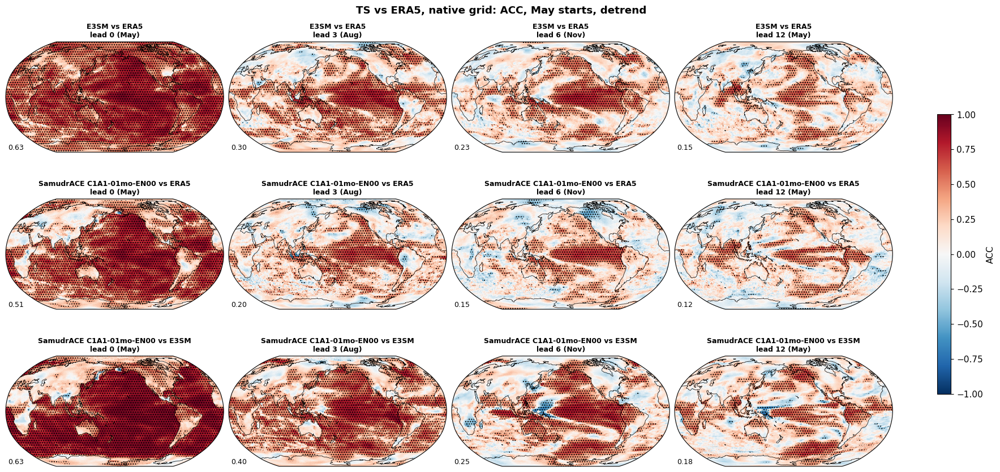

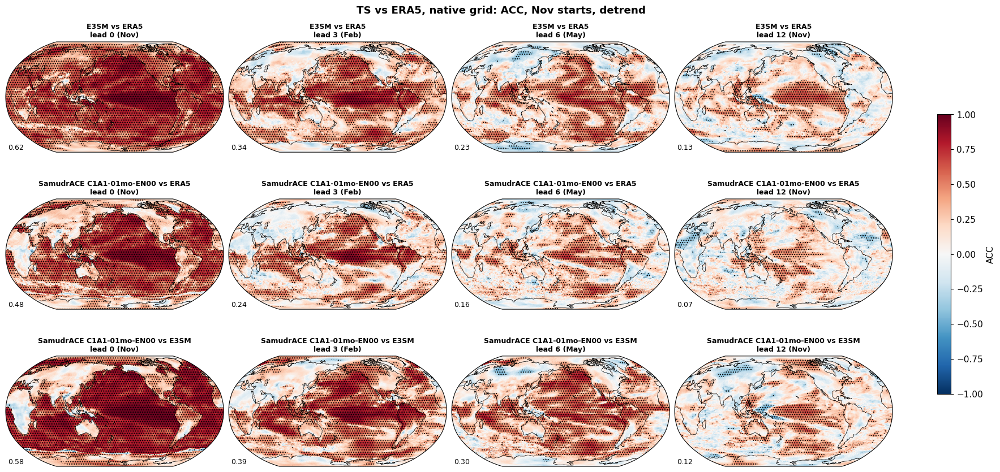

In [6]:
def plot_skill_maps(metric, init_month):
    cmap, vmin, vmax, cbar_label = {
        "corr": ("RdBu_r", -1, 1, "ACC"),
        "rmse": ("RdBu", 0, 2, "nRMSE (RMSE / σ_ref)"),
    }[metric]
    fig, axes = plt.subplots(
        len(COMPARISONS), len(MAP_LEADS), figsize=(4.4 * len(MAP_LEADS), 2.6 * len(COMPARISONS) + 0.8),
        subplot_kw={"projection": ccrs.Robinson(central_longitude=180)}, squeeze=False, constrained_layout=True,
    )
    for row, (f, r) in zip(axes, COMPARISONS):
        ds = skill[(f, r, init_month)]
        for ax, lead in zip(row, MAP_LEADS):
            sel = ds.sel(L=lead + 1)
            im = ax.pcolormesh(ds["lon"], ds["lat"], sel[metric], transform=ccrs.PlateCarree(),
                               cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
            if metric == "corr":
                significant = (sel["pval"] < ALPHA).where(sel["corr"].notnull())
                ax.contourf(ds["lon"], ds["lat"], significant, levels=[0.5, 1.5], colors="none",
                            hatches=["...."], transform=ccrs.PlateCarree())
            ax.coastlines(linewidth=0.5)
            ax.set_title(f"{DISPLAY.get(f, f)} vs {DISPLAY.get(r, r)}\nlead {lead} ({verification_month(init_month, lead)})",
                         fontsize=9, fontweight="bold")
            ax.text(0.01, 0.02, f"{float(area_mean(sel[metric])):.2f}", transform=ax.transAxes, fontsize=9,
                    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label=cbar_label)
    fig.suptitle(f"{label}: {cbar_label}, {month_abbr[init_month]} starts, {TREND_TAG}", fontweight="bold")
    save(fig, f"{VARIABLE}_{metric}_maps_init{init_month:02d}_{GRID_TAG}_{TREND_TAG}.png")
    plt.show()


for init_month in INIT_MONTHS:
    plot_skill_maps("corr", init_month)

### 2b. nRMSE maps

Red (nRMSE < 1) beats a climatological forecast; blue is worse.

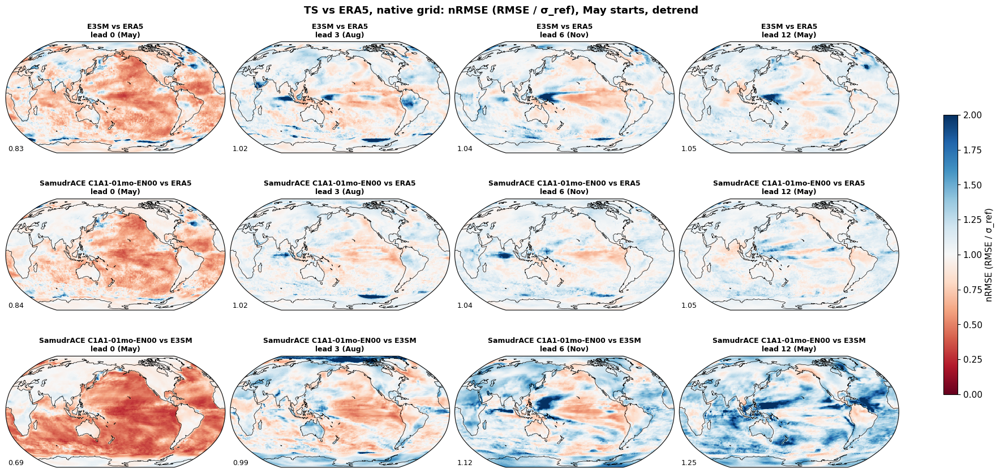

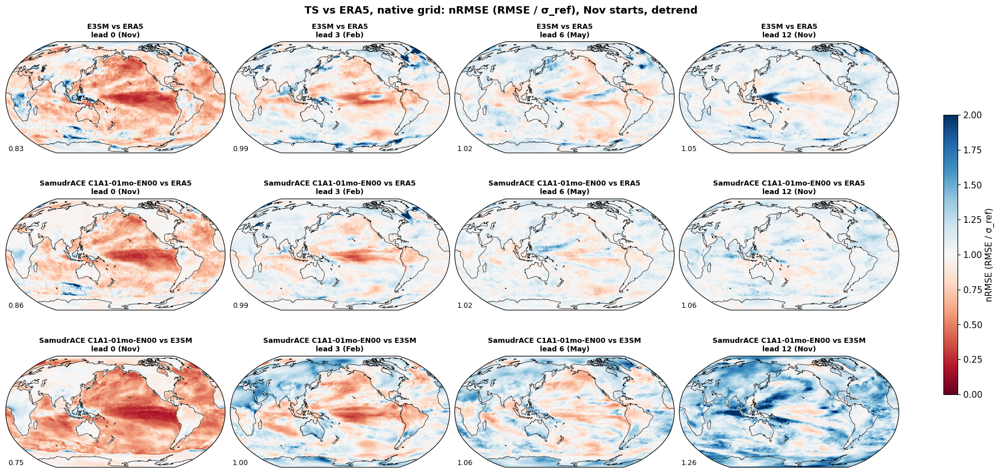

In [7]:
for init_month in INIT_MONTHS:
    plot_skill_maps("rmse", init_month)

### 2c. Regional mean of gridpoint skill vs lead

Area-weighted means of the gridpoint ACC and nRMSE maps (not the skill of a regional-mean index). Solid lines are May starts, dashed lines November starts.

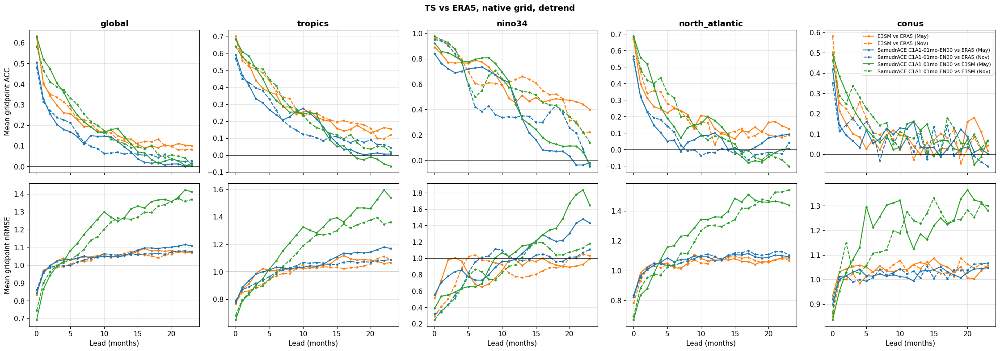

--- global: mean gridpoint ACC / nRMSE at leads [0, 3, 6, 12]
                        E3SM vs ERA5       May: +0.63/0.83  +0.30/1.02  +0.23/1.04  +0.15/1.05
                        E3SM vs ERA5       Nov: +0.62/0.83  +0.34/0.99  +0.23/1.02  +0.13/1.05
    SamudrACE C1A1-01mo-EN00 vs ERA5       May: +0.51/0.84  +0.20/1.02  +0.15/1.04  +0.12/1.05
    SamudrACE C1A1-01mo-EN00 vs ERA5       Nov: +0.48/0.86  +0.24/0.99  +0.16/1.02  +0.07/1.06
    SamudrACE C1A1-01mo-EN00 vs E3SM       May: +0.63/0.69  +0.40/0.99  +0.25/1.12  +0.18/1.25
    SamudrACE C1A1-01mo-EN00 vs E3SM       Nov: +0.58/0.75  +0.39/1.00  +0.30/1.06  +0.12/1.26
--- tropics: mean gridpoint ACC / nRMSE at leads [0, 3, 6, 12]
                        E3SM vs ERA5       May: +0.70/0.77  +0.44/0.99  +0.36/1.01  +0.22/1.04
                        E3SM vs ERA5       Nov: +0.69/0.77  +0.51/0.89  +0.38/0.97  +0.25/1.03
    SamudrACE C1A1-01mo-EN00 vs ERA5       May: +0.59/0.78  +0.33/0.98  +0.24/1.03  +0.21/1.04
    SamudrACE C1A1-0

In [14]:
month_styles = dict(zip(INIT_MONTHS, ["-", "--", ":", "-."]))
fig, axes = plt.subplots(2, len(SUMMARY_REGIONS), figsize=(4.5 * len(SUMMARY_REGIONS), 8), sharex=True, squeeze=False)
regional = {}
for col, region_name in enumerate(SUMMARY_REGIONS):
    for (f, r), color in zip(COMPARISONS, COMPARISON_COLORS):
        for init_month in INIT_MONTHS:
            ds = skill[(f, r, init_month)]
            for row, metric in enumerate(("corr", "rmse")):
                series = area_mean(select_region(ds[metric], REGIONS[region_name]))
                regional[(region_name, metric, f, r, init_month)] = series
                axes[row, col].plot(ds["L"] - 1, series, month_styles[init_month], color=color, marker="o", ms=2.5,
                                    label=f"{DISPLAY.get(f, f)} vs {DISPLAY.get(r, r)} ({month_abbr[init_month]})")
    axes[0, col].set_title(region_name, fontweight="bold")
    axes[0, col].axhline(0, color="k", lw=0.5)
    axes[1, col].axhline(1, color="k", lw=0.5)
    axes[1, col].set_xlabel("Lead (months)")
    for ax in axes[:, col]:
        ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("Mean gridpoint ACC")
axes[1, 0].set_ylabel("Mean gridpoint nRMSE")
axes[0, -1].legend(fontsize=8)
fig.suptitle(f"{label}, {TREND_TAG}", fontweight="bold")
plt.tight_layout()
save(fig, f"{VARIABLE}_regional_skill_{GRID_TAG}_{TREND_TAG}.png")
plt.show()

summary_leads = [0, 3, 6, 12]
for region_name in SUMMARY_REGIONS:
    print(f"--- {region_name}: mean gridpoint ACC / nRMSE at leads {summary_leads}")
    for f, r in COMPARISONS:
        for init_month in INIT_MONTHS:
            acc_values = regional[(region_name, "corr", f, r, init_month)].sel(L=[l + 1 for l in summary_leads]).values
            rmse_values = regional[(region_name, "rmse", f, r, init_month)].sel(L=[l + 1 for l in summary_leads]).values
            pairs_text = "  ".join(f"{a:+.2f}/{b:.2f}" for a, b in zip(acc_values, rmse_values))
            print(f"  {DISPLAY.get(f, f):>26s} vs {DISPLAY.get(r, r):<10s} {month_abbr[init_month]}: {pairs_text}")

## 3. Niño 3.4 index skill

Niño 3.4 is the cosine-weighted TS mean over 5°S–5°N, 170°W–120°W, taken on the native grid without a surface mask, independently of `VARIABLE`. The same three comparisons are scored against `NINO_OBS_PRODUCT`. With `INCLUDE_PSL_INDEX`, E3SM and SamudrACE are also scored against the NOAA PSL HadISST Niño 3.4 index (thin dotted lines) as a reference-sensitivity check. Filled markers are significant at `ALPHA`.

Index time series are cached in `skill_cache/nino34/` because computing them reads the full TS files.

In [15]:
nino_paths = merged_paths("TS", NINO_OBS_PRODUCT)
nino_index = {}
for name, path in nino_paths.items():
    cache_path = CACHE_DIR / "nino34" / f"{FILE_TAGS[name]}_TS_nino34.nc"
    if cache_path.exists() and not FORCE_RECOMPUTE:
        nino_index[name] = load_netcdf(cache_path)["nino34"]
        continue
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}; run 0-regrid-obs.ipynb for observations")
    with xr.open_dataset(path) as ds:
        index = area_mean(select_region(ds["TS"], NINO_REGION)).load().rename("nino34")
    atomic_to_netcdf(index.to_dataset().assign_attrs(source_file=str(path), region=str(NINO_REGION)), cache_path)
    nino_index[name] = index
    print(f"cached {cache_path}")

nino_common = sorted(set.intersection(*(set(da["start_date"].values) for da in nino_index.values())))
nino_index = {name: da.sel(start_date=nino_common) for name, da in nino_index.items()}
psl_nino34 = index_reference_skill.load_psl_index("Nino3.4") if INCLUDE_PSL_INDEX else None
print(f"Niño 3.4: {len(nino_common)} common start dates {str(nino_common[0])[:7]} ... {str(nino_common[-1])[:7]}")

NINO_COMPARISONS = [("E3SM", NINO_OBS_PRODUCT), ("SamudrACE", NINO_OBS_PRODUCT), ("SamudrACE", "E3SM")]
nino_skill = {}
for init_month in INIT_MONTHS:
    layout = {name: to_esp_layout(da, init_month) for name, da in nino_index.items()}
    leads = layout["E3SM"][0]["L"].values
    for f, r in NINO_COMPARISONS:
        nino_skill[(f, r, init_month)] = xr.concat([
            pair_skill(layout[f][0].sel(L=[L]), layout[f][1].sel(L=[L]), layout[r][0].sel(L=[L]), layout[r][1].sel(L=[L]))
            for L in leads], dim="L")
    if INCLUDE_PSL_INDEX:
        for f in ("E3SM", "SamudrACE"):
            nino_skill[(f, "PSL", init_month)] = xr.concat([
                pair_skill(layout[f][0].sel(L=[L]), layout[f][1].sel(L=[L]), psl_nino34) for L in leads], dim="L")

Niño 3.4: 78 common start dates 1980-05 ... 2018-11


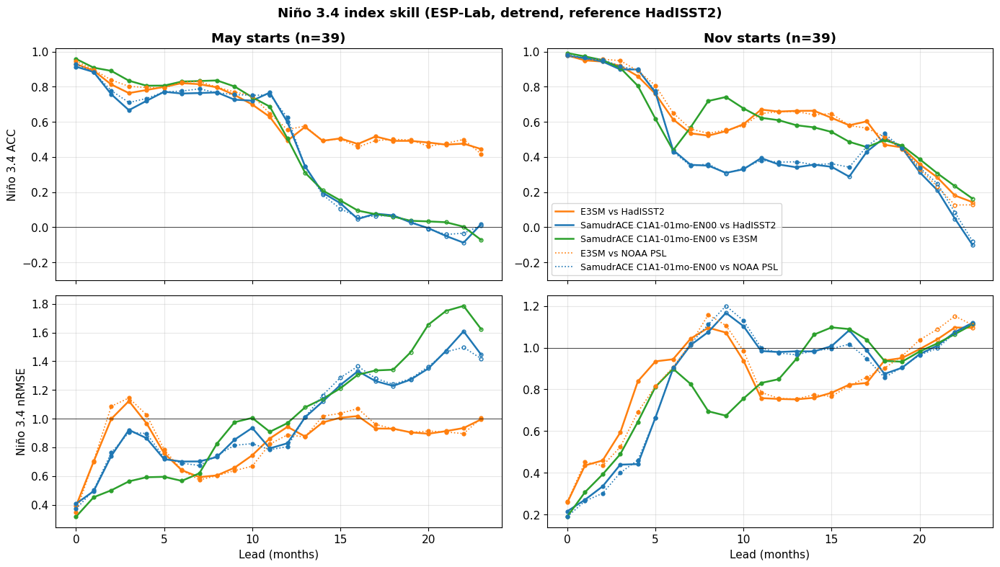

                      E3SM vs HadISST2   May  ACC/nRMSE  L0: +0.93/0.39  L3: +0.76/1.12  L6: +0.82/0.64  L12: +0.49/0.94
  SamudrACE C1A1-01mo-EN00 vs HadISST2   May  ACC/nRMSE  L0: +0.91/0.41  L3: +0.67/0.92  L6: +0.76/0.70  L12: +0.60/0.83
  SamudrACE C1A1-01mo-EN00 vs E3SM       May  ACC/nRMSE  L0: +0.96/0.32  L3: +0.83/0.56  L6: +0.83/0.57  L12: +0.51/0.97
                      E3SM vs PSL        May  ACC/nRMSE  L0: +0.95/0.35  L3: +0.80/1.14  L6: +0.83/0.64  L12: +0.56/0.89
  SamudrACE C1A1-01mo-EN00 vs PSL        May  ACC/nRMSE  L0: +0.93/0.37  L3: +0.71/0.90  L6: +0.78/0.69  L12: +0.63/0.80
                      E3SM vs HadISST2   Nov  ACC/nRMSE  L0: +0.98/0.26  L3: +0.92/0.59  L6: +0.61/0.94  L12: +0.66/0.75
  SamudrACE C1A1-01mo-EN00 vs HadISST2   Nov  ACC/nRMSE  L0: +0.98/0.22  L3: +0.90/0.44  L6: +0.44/0.90  L12: +0.36/0.98
  SamudrACE C1A1-01mo-EN00 vs E3SM       Nov  ACC/nRMSE  L0: +0.99/0.19  L3: +0.91/0.49  L6: +0.44/0.90  L12: +0.61/0.85
                      E3SM vs PS

In [16]:
nino_styles = {pair: dict(color=color, ls="-", lw=1.8) for pair, color in zip(NINO_COMPARISONS, COMPARISON_COLORS)}
nino_styles.update({("E3SM", "PSL"): dict(color="tab:orange", ls=":", lw=1.2),
                    ("SamudrACE", "PSL"): dict(color="tab:blue", ls=":", lw=1.2)})

fig, axes = plt.subplots(2, len(INIT_MONTHS), figsize=(7 * len(INIT_MONTHS), 8), sharex=True, squeeze=False)
for col, init_month in enumerate(INIT_MONTHS):
    for (f, r), style in nino_styles.items():
        if (f, r, init_month) not in nino_skill:
            continue
        ds = nino_skill[(f, r, init_month)]
        lead = ds["L"] - 1
        reference_name = "NOAA PSL" if r == "PSL" else DISPLAY.get(r, r)
        for row, metric in enumerate(("corr", "rmse")):
            ax = axes[row, col]
            ax.plot(lead, ds[metric], label=f"{DISPLAY.get(f, f)} vs {reference_name}", **style)
            significant = ds["pval"] < ALPHA
            ax.plot(lead.where(significant), ds[metric].where(significant), "o", color=style["color"], ms=3.5)
            ax.plot(lead.where(~significant), ds[metric].where(~significant), "o", mfc="none", color=style["color"], ms=3.5)
    n_starts = int(nino_skill[(*NINO_COMPARISONS[0], init_month)]["sample_count"].isel(L=0))
    axes[0, col].set_title(f"{month_abbr[init_month]} starts (n={n_starts})", fontweight="bold")
    axes[0, col].axhline(0, color="k", lw=0.5)
    axes[0, col].set_ylim(-0.3, 1.02)
    axes[1, col].axhline(1, color="k", lw=0.5)
    axes[1, col].set_xlabel("Lead (months)")
    for ax in axes[:, col]:
        ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("Niño 3.4 ACC")
axes[1, 0].set_ylabel("Niño 3.4 nRMSE")
axes[0, -1].legend(fontsize=9)
fig.suptitle(f"Niño 3.4 index skill (ESP-Lab, {TREND_TAG}, reference {NINO_OBS_PRODUCT})", fontweight="bold")
plt.tight_layout()
save(fig, f"nino34_skill_{TREND_TAG}.png")
plt.show()

for (f, r, init_month), ds in nino_skill.items():
    values = "  ".join(f"L{l}: {float(ds['corr'].sel(L=l + 1)):+.2f}/{float(ds['rmse'].sel(L=l + 1)):.2f}" for l in summary_leads)
    print(f"{DISPLAY.get(f, f):>26s} vs {DISPLAY.get(r, r):<10s} {month_abbr[init_month]}  ACC/nRMSE  {values}")